In [1]:
from src.data_generator import DataGenerator
from src.gaussian_mixture import GaussianMixtureMAR
from src.metrics import energy_distance, energy_distance_faster
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy.stats import norm
from joblib import Parallel, delayed

from torch.distributions import MultivariateNormal, Normal, Categorical

In [ ]:
class MotivatingExample:

    def __init__(self, type='mar', n=5000, alpha=0.7, model_k=(0,10), p=0.1, B=100, n_jobs=15, device='cpu', dtype=torch.float32):
        self.n = n
        self.alpha = alpha
        self.model_k = model_k
        self.p = p
        self.B = B
        self.n_jobs = n_jobs
        self.device = device
        self.dtype = dtype

        get_X_funcs = {
            'mar': self._get_X_mar,
            'mar_like': self._get_X_mar,
            'mnar': self._get_X_mnar
        }

        get_M_funcs = {
            'mar': self._get_M_mar,
            'mar_like': self._get_M_mar_like,
            'mnar': self._get_M_mnar
        }

        self.get_X = get_X_funcs[type]
        self.get_M = get_M_funcs[type]

    def _get_X_mar(self):
        loc = torch.zeros(2, device=self.device, dtype=self.dtype)
        cov = torch.tensor(
            [
                [1.0, self.alpha],
                [self.alpha, 1.0]
            ],
            device=self.device,
            dtype=self.dtype
        )
        return MultivariateNormal(loc, cov).sample((self.n,))

    def _get_X_mnar(self):
        loc = torch.zeros(2, device=self.device, dtype=self.dtype)
        cov = torch.eye(2, device=self.device, dtype=self.dtype)
        return MultivariateNormal(loc, cov).sample((self.n,))

    def _X_to_U(self, X):
        norm = Normal(0,1)
        x1 = X[:, 0]
        x2 = X[:, 0]
        u1 = norm.cdf(x1)
        u2 = norm.cdf(x2)
        return u1, u2

    def _get_M(self, probs):
        outcomes = torch.tensor(
            [
                [1,1], [1,0], [0,1]
            ],
            device=self.device,
            dtype=self.dtype
        )
        idx = Categorical(probs).sample()
        return outcomes[idx]

    def _get_M_mar(self, X):
        u1, u2 = self._X_to_U(X)
        probs = torch.stack((u1+u2, 2-u1, 1-u2), dim=1) / 3
        return self._get_M(probs)
        

    def _get_M_mnar(self, X):
        u1, u2 = self._X_to_U(X)
        probs = torch.stack((u1+u2, 2-u2, 1-u1), dim=1) / 3
        return self._get_M(probs)

    def _get_M_mar_like(self, X):
        u1, u2 = self._X_to_U(X)
        p1 = torch.ones_like(u1, device=self.device, dtype=self.dtype)
        prod = (u1 - 0.5) * (u2 - 0.5)
        probs = torch.stack((p1, 0.5-prod, 0.5+prod), dim=1) / 2
        return self._get_M(probs)

    def _get_Xtildes(self, X, M):
        model = GaussianMixtureMAR(self.model_k)
        model.fit(X, M)
        return model.sample(self.n)[0], model.impute(X, M)
    
    def _conditional(self, x):
        mean = self.alpha * x
        std = torch.sqrt(torch.tensor(1.0 - self.alpha**2, device=x.device))
        return torch.distributions.Normal(mean, std).sample()

    def _get_conditional_Xtest(self, X, M):
        """
        p0(xmb|xm)
        """
        Xt1 = X.clone()
        Xt2 = X.clone()
        Xt1[:,0] = self._conditional(X[:,1])
        Xt2[:,1] = self._conditional(X[:,0])
        cond1 = (M==1).all(dim=1)[:, None] # all observed
        cond2 = (M==torch.tensor([0,1,1], device=M.device)).all(dim=1)[:, None] # X1 missing
        return torch.where(cond1, X, torch.where(cond2, Xt1, Xt2))

    def _evaluate(self):
        X = self.get_X()
        Xtest = self.get_X()
        M = self.get_M(X)
        Xtilde1, Xtilde2 = self._get_Xtildes(X, M)
        qx1_gen = np.quantile(Xtilde1[:,0], self.p).item()
        qx1_imp = np.quantile(Xtilde2[:,0], self.p).item()
        corr_gen = torch.corrcoef(Xtilde1[:, :2].T)[0, 1].item()
        corr_imp = torch.corrcoef(Xtilde2[:, :2].T)[0, 1].item()
        ed_gen = energy_distance(Xtest, Xtilde1).item()
        ed_imp = energy_distance(Xtest, Xtilde2).item()
        scaled_ed_gen = energy_distance_faster(Xtest, Xtilde1, scale=True).item()
        scaled_ed_imp = energy_distance_faster(Xtest, Xtilde2, scale=True).item()

        return qx1_gen, qx1_imp, corr_gen, corr_imp, ed_gen, ed_imp, scaled_ed_gen, scaled_ed_imp

    def evaluate(self):
        results = np.array(
            Parallel(self.n_jobs)(
                delayed(self._evaluate)()
                for _ in range(self.B)
            )
        )
        results = pd.DataFrame(
            results, 
            columns=['qx1_gen', 'qx1_imp', 'corr_gen', 'corr_imp', 'ed_gen', 'ed_imp', 'scaled_ed_gen', 'scaled_ed_imp']
            )
        return results


In [3]:
B = 500

res = {
    'mar': np.empty((100, 8)),
    'mar_like': np.empty((100, 8)),
    'mnar': np.empty((100, 8))
}

types = ['mar', 'mar_like', 'mnar']

for m in types:
    me = MotivatingExample(type=m, B=B)
    res[m] = me.evaluate()

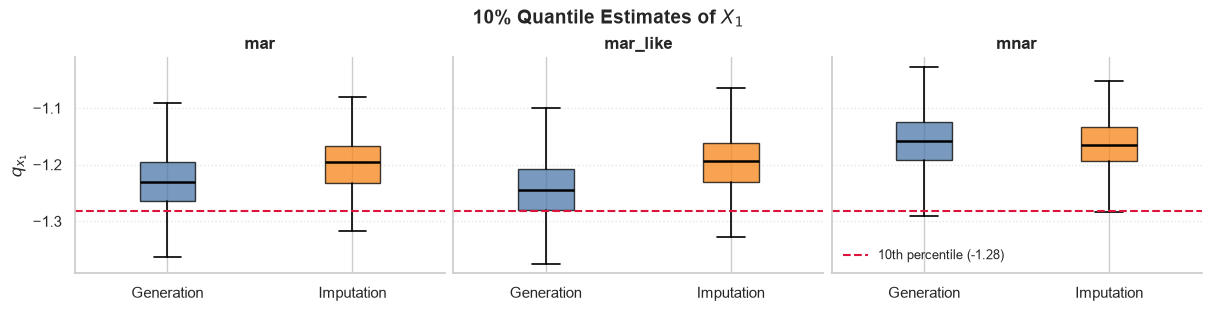

In [7]:
sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(
    1, len(types),
    figsize=(4 * len(types), 3),
    sharey=True,
    constrained_layout=True
)

if len(types) == 1:
    axes = [axes]

q10 = norm.ppf(0.1)

for ax, m in zip(axes, types):
    data = res[m][["qx1_gen", "qx1_imp"]]

    bp = ax.boxplot(
        data,
        tick_labels=["Generation", "Imputation"],
        patch_artist=True,
        widths=0.3,
        showfliers=False,
        medianprops=dict(color="black", linewidth=1.8),
        whiskerprops=dict(linewidth=1.2),
        capprops=dict(linewidth=1.2),
    )

    for patch, color in zip(bp["boxes"], ["#4C78A8", "#F58518"]):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)

    ax.axhline(
        q10,
        color="crimson",
        linestyle="--",
        linewidth=1.5,
        label=f"10th percentile ({q10:.2f})"
    )

    ax.set_title(str(m), fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.grid(axis="y", linestyle=":", alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel(r"$q_{x_1}$")
axes[-1].legend(frameon=False, fontsize=9, loc="best")

fig.suptitle(
    r" 10% Quantile Estimates of $X_1$",
    fontsize=14,
    fontweight="bold"
)

plt.show()

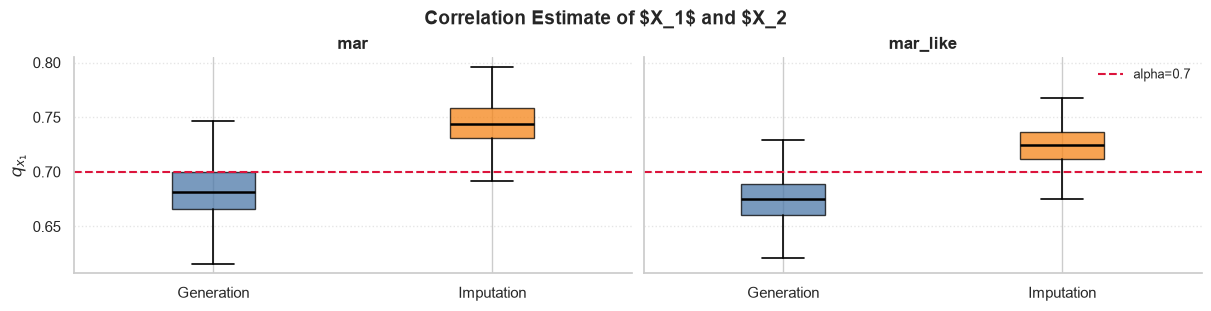

In [8]:
sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(
    1, len(types)-1,
    figsize=(4 * len(types), 3),
    sharey=True,
    constrained_layout=True
)

if len(types) == 1:
    axes = [axes]

corr0 = me.alpha

for ax, m in zip(axes, types[:2]):
    data = res[m][["corr_gen", "corr_imp"]]

    bp = ax.boxplot(
        data,
        tick_labels=["Generation", "Imputation"],
        patch_artist=True,
        widths=0.3,
        showfliers=False,
        medianprops=dict(color="black", linewidth=1.8),
        whiskerprops=dict(linewidth=1.2),
        capprops=dict(linewidth=1.2),
    )

    for patch, color in zip(bp["boxes"], ["#4C78A8", "#F58518"]):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)

    ax.axhline(
        corr0,
        color="crimson",
        linestyle="--",
        linewidth=1.5,
        label=f"alpha={me.alpha}"
    )

    ax.set_title(str(m), fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.grid(axis="y", linestyle=":", alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel(r"$q_{x_1}$")
axes[-1].legend(frameon=False, fontsize=9, loc="best")

fig.suptitle(
    r"Correlation Estimate of $X_1$ and $X_2",
    fontsize=14,
    fontweight="bold"
)

plt.show()

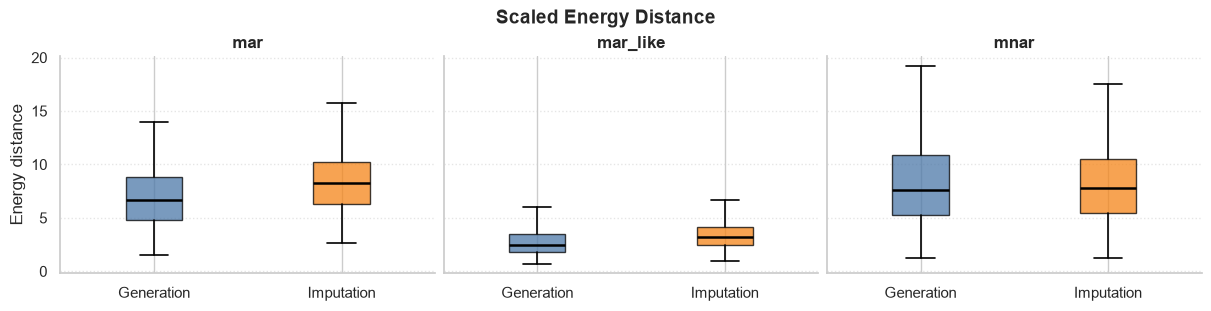

In [9]:
sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(
    1, len(types),
    figsize=(4 * len(types), 3),
    sharey=True,
    constrained_layout=True
)

if len(types) == 1:
    axes = [axes]

q10 = norm.ppf(0.1)

for ax, m in zip(axes, types):
    data = res[m][["scaled_ed_gen", "scaled_ed_imp"]]

    bp = ax.boxplot(
        data,
        tick_labels=["Generation", "Imputation"],
        patch_artist=True,
        widths=0.3,
        showfliers=False,
        medianprops=dict(color="black", linewidth=1.8),
        whiskerprops=dict(linewidth=1.2),
        capprops=dict(linewidth=1.2),
    )

    for patch, color in zip(bp["boxes"], ["#4C78A8", "#F58518"]):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)

    ax.set_title(str(m), fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.grid(axis="y", linestyle=":", alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Energy distance")

fig.suptitle(
    r"Scaled Energy Distance",
    fontsize=14,
    fontweight="bold"
)

plt.show()